Goals of the notebook:

- Cluster the vascular cells
- Save out labelmat

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import yaml 
from pathlib import Path 

import numpy as np
import pandas as pd
import scanpy as sc
from dotenv import dotenv_values
import matplotlib.pyplot as plt 

from hm3d_utils.clustering import run_decomposition
from hm3d_utils.plotting import zoom_umap

In [3]:
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])
CLUSTERING_DIR = DATADIR / "5_clustering"
MODELDIR = CLUSTERING_DIR / 'all_control'
DATASETS_DIR = MODELDIR / "datasets"


In [4]:
PARAMS_FILE = Path("resources", "clustering_params.yaml")

In [5]:
CELL_TYPE = "Vasc"

if CELL_TYPE == "Neuro":
    adata_fp = DATASETS_DIR / 'neuronal_raw_embed_propagated.h5ad'
else:
    adata_fp = DATASETS_DIR / 'glial_raw_embed_propagated.h5ad'

In [6]:

with open(PARAMS_FILE, "r") as fp:
            parameters = yaml.safe_load(fp)

parameters

{'loop': {'initial_solution_key': 'L1', 'max_levels': 10},
 'neighbors': {'n_neighbors': 15, 'use_rep': 'X_embed'},
 'leiden': {'n_iterations': 5, 'n_jobs': 20, 'n_seeds': 100, 'resolution': []},
 'consensus': {'random_state': 0},
 'pruning': {'max_stratum_size': 10000,
  'min_stratum_size': 10,
  'min_cluster_size': 100,
  'min_marker_genes': 30,
  'symmetric_intermediate_resolution': True,
  'symmetric_highest_resolution': False,
  'min_pct_expression': 0.1,
  'min_specificity': 0.2,
  'min_strata': 2,
  'nn_checks': 2,
  'random_state': 0,
  'significance_threshold': 0.001,
  'strata_key': 'Sample',
  'use_rep': 'X_embed'},
 'masking': {'enabled': False,
  'min_nn_agreement': 0.5,
  'n_neighbors': 40,
  'use_rep': 'X_embed'}}

In [7]:
adata = sc.read_h5ad(adata_fp, backed="r")
if CELL_TYPE == "Neuro":
    load_mask = adata.obs.IsControl
else:
    load_mask = (adata.obs["major_features_propagated"].str.contains(CELL_TYPE)) & (adata.obs.IsControl)

adata = adata[load_mask].to_memory()

adata.obs["L1"] = adata.obs.major_features_propagated.copy()
# Remove excluded genes
adata = adata[:, ~adata.var.IsHvgExcludedGene]

sc.pp.normalize_total(adata, target_sum=10_000)

/beegfs/home/mfeldmann/repos/HypoMap3D/.venv/lib/python3.11/site-packages/scanpy/preprocessing/_normalization.py:269: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


In [8]:
# for later plotting of gene expression
adata.layers["log1p"] = adata.X.copy()
sc.pp.log1p(adata, layer="log1p")

In [9]:
adata

AnnData object with n_obs × n_vars = 22628 × 55371
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'cluster_id_label', 'supertype_id_label', 'subclass_id_label', 'class_id_label', 'C66_named', 'C185_named', 'C286_named', 'C465_named', 'ABC_class_propagated', 'ABC_class_confidence', 'to_be_removed', 'IsNeuronal', 'major_features', 'major_features_propagated', 'major_features_confidence', 'ABC_supertype_propagated', 'ABC_supertype_confidence', 'ABC_subclass_propagated', 'ABC_subclass_confidence', 'ABC_cluster_propagated', 'ABC_cluster_confidence', 'L1'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    uns: 'neighbors', 'tsne', 'umap', 'log1p'

### Decomposing L1

In [10]:
for res in [0.1]: 

    labelmat = run_decomposition(
        adata,
        use_rep = parameters["neighbors"]["use_rep"],
        init_key = parameters["loop"]["initial_solution_key"],
        max_levels = 1,
        n_neighbors = parameters["neighbors"]["n_neighbors"],
        resolutions = [res],
        n_seeds = parameters["leiden"]["n_seeds"],
        n_iterations = parameters["leiden"]["n_iterations"],
        n_jobs = parameters["leiden"]["n_jobs"],
        strata_key = parameters["pruning"]["strata_key"],
        nn_checks = parameters["pruning"]["nn_checks"],
        min_cluster_size = parameters["pruning"]["min_cluster_size"],
        min_stratum_size = parameters["pruning"]["min_stratum_size"],
        max_stratum_size = parameters["pruning"]["max_stratum_size"],
        min_strata = parameters["pruning"]["min_strata"],
        min_pct_expression = parameters["pruning"]["min_pct_expression"],
        min_specificity = parameters["pruning"]["min_specificity"],
        significance_threshold = parameters["pruning"]["significance_threshold"],
        min_marker_genes = parameters["pruning"]["min_marker_genes"],
        symmetric = parameters["pruning"]["symmetric_intermediate_resolution"],
        masking_enabled = parameters["masking"]["enabled"],
        min_nn_agreement = parameters["masking"]["min_nn_agreement"],
        random_state = parameters["pruning"]["random_state"]
    )

    labelmat = pd.Series(labelmat[:, -1], index=adata.obs.index).replace('-1', pd.NA).astype("category")

    adata.obs[f"L2_new_{res}"] = labelmat


0 vs 4 passed with 563 vs 720 markers
2 vs 5 passed with 478 vs 210 markers
0 vs 5 passed with 1084 vs 417 markers
2 and 4 merged due to insufficient valid overlapping strata.
	>>4 and 2 merged to make 4_2
0 vs 4_2 passed with 595 vs 365 markers
5 vs 4_2 passed with 363 vs 885 markers
1 vs 4_2 passed with 897 vs 982 markers
0 vs 1 passed with 1536 vs 859 markers
3 or 4_2 merged due to insufficient cluster size 41/2609.
	>>4_2 and 3 merged to make 4_2_3
0 vs 4_2_3 passed with 580 vs 378 markers
5 vs 4_2_3 passed with 358 vs 934 markers
1 vs 4_2_3 passed with 880 vs 1055 markers
Step finished with  0.00% of obs locked and 4 clusters.                                                                                           


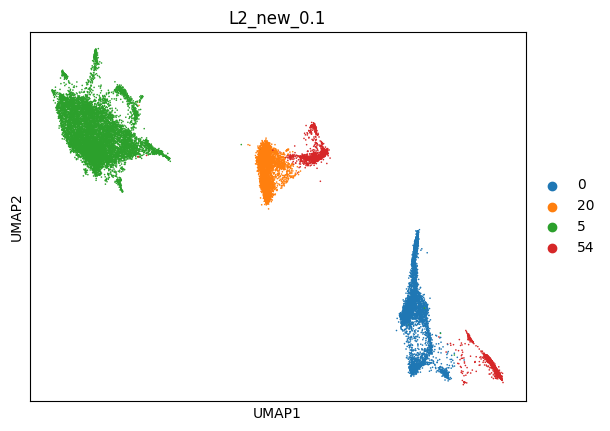

In [11]:
final_l2_col = "L2_new_0.1"
zoom_umap(adata, interest_mask = np.ones(adata.n_obs, dtype=bool), color=[final_l2_col], ncols=1, include_background=False, clip_pct=0.01)

The part of cluster 54 that is at the bottom right corner are VLMC cells as evidenced by the expression of some markers that were also shown by ABC for VLMC subclusters.

To have the VLMC vs rest split happening on L2, that part of cluster 54 was changed manually to stick to the other VLMC subclusters that are on cluster 0


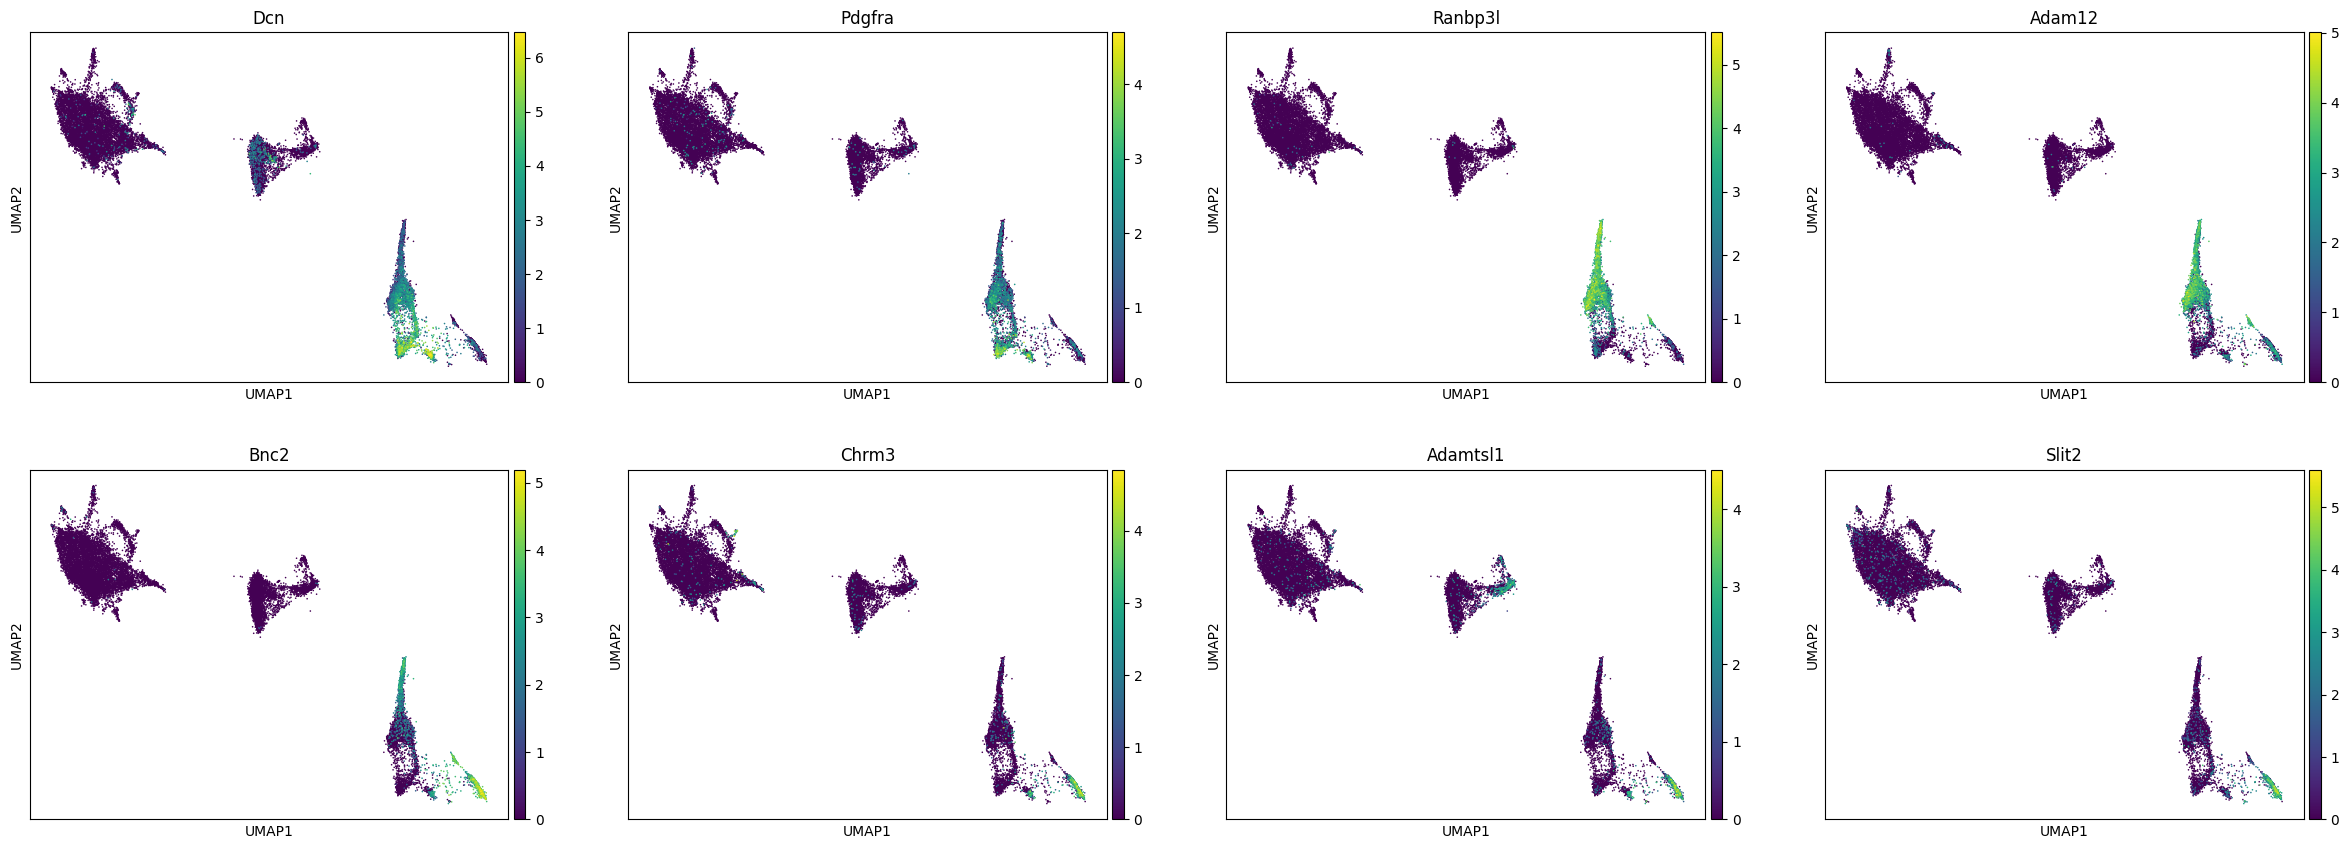

In [13]:
zoom_umap(adata, interest_mask = np.ones(adata.n_obs, dtype=bool), color=["Dcn", "Pdgfra", "Ranbp3l", "Adam12", "Bnc2", "Chrm3", "Adamtsl1", "Slit2"], ncols=4, include_background=False, clip_pct=0.01, layer="log1p")

In [12]:
adata.obs["L2_new_0.1_manual"] = adata.obs["L2_new_0.1"].copy() 
adata.obs.loc[(adata.obs["L2_new_0.1"] == "54") & (adata.obsm["X_umap"][:, 0] > 5), "L2_new_0.1_manual"] = "0"

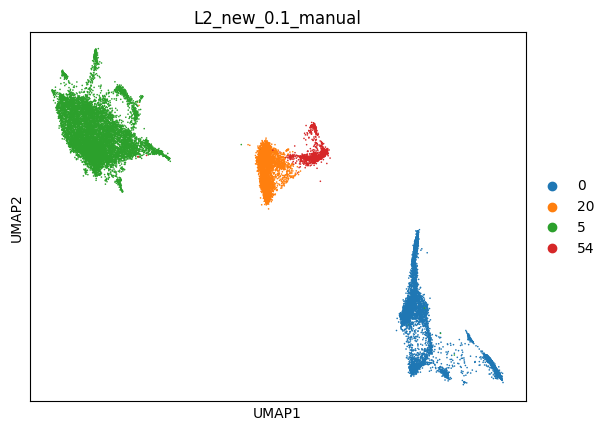

In [14]:
final_l2_col = "L2_new_0.1_manual"
zoom_umap(adata, interest_mask = np.ones(adata.n_obs, dtype=bool), color=[final_l2_col], ncols=1, include_background=False, clip_pct=0.01)

### Decomposing level 2

Unfortunately, it was not possible to get a clustering of similar granularity for all subclasses using the same parameters.

Hence, we merged two different resolutions. 

In [15]:
symmetric = parameters["pruning"]["symmetric_intermediate_resolution"]

for res in [0.05, 0.22,]: 

    res_str = "_".join([str(r) for r in res]) if isinstance(res, list) else res

    print(res_str)

    labelmat = run_decomposition(
        adata,
        use_rep = parameters["neighbors"]["use_rep"],
        init_key = final_l2_col,
        max_levels = 10,#parameters["loop"]["max_levels"],
        n_neighbors = parameters["neighbors"]["n_neighbors"],
        resolutions = res if isinstance(res, list) else [res],
        n_seeds = parameters["leiden"]["n_seeds"],
        n_iterations = parameters["leiden"]["n_iterations"],
        n_jobs = parameters["leiden"]["n_jobs"],
        strata_key = parameters["pruning"]["strata_key"],
        nn_checks = parameters["pruning"]["nn_checks"],
        min_cluster_size = parameters["pruning"]["min_cluster_size"],
        min_stratum_size = parameters["pruning"]["min_stratum_size"],
        max_stratum_size = parameters["pruning"]["max_stratum_size"],
        min_strata = parameters["pruning"]["min_strata"],
        min_pct_expression = parameters["pruning"]["min_pct_expression"],
        min_specificity = parameters["pruning"]["min_specificity"],
        significance_threshold = parameters["pruning"]["significance_threshold"],
        min_marker_genes = parameters["pruning"]["min_marker_genes"],
        symmetric = symmetric,
        masking_enabled = parameters["masking"]["enabled"],
        min_nn_agreement = parameters["masking"]["min_nn_agreement"],
        random_state = parameters["pruning"]["random_state"],
        level=1 # start at level idx 1 as you have decomposed the 0th level before
    )

    labelmat = pd.Series(labelmat[:, -1], index=adata.obs.index).replace('-1', pd.NA).astype("category")


    adata.obs[f"L3_new_{res}"] = labelmat


0.05
1 vs 2 passed with 275 vs 164 markers
0 vs 1 passed with 721 vs 636 markers
0 vs 2 passed with 480 vs 303 markers
0 or 1 merged due to insufficient cluster size 1389/41.
	>>1 and 0 merged to make 1_0
Step finished with  70.78% of obs locked and 6 clusters.                                                                                           
0 vs 1 FAILED with 54 vs 15 markers
	>>1 and 0 merged to make 1_0
Step finished with  100.00% of obs locked and 6 clusters.                                                                                           
0.22
4 vs 6 passed with 82 vs 47 markers
5 vs 6 FAILED with 335 vs 0 markers
	>>6 and 5 merged to make 6_5
4 vs 6_5 passed with 76 vs 58 markers
3 vs 4 passed with 118 vs 32 markers
1 vs 4 FAILED with 37 vs 25 markers
	>>4 and 1 merged to make 4_1
6_5 vs 4_1 passed with 54 vs 72 markers
3 vs 4_1 passed with 117 vs 30 markers
2 vs 6_5 FAILED with 15 vs 0 markers
	>>6_5 and 2 merged to make 6_5_2
4_1 vs 6_5_2 passed with 70 vs 52 

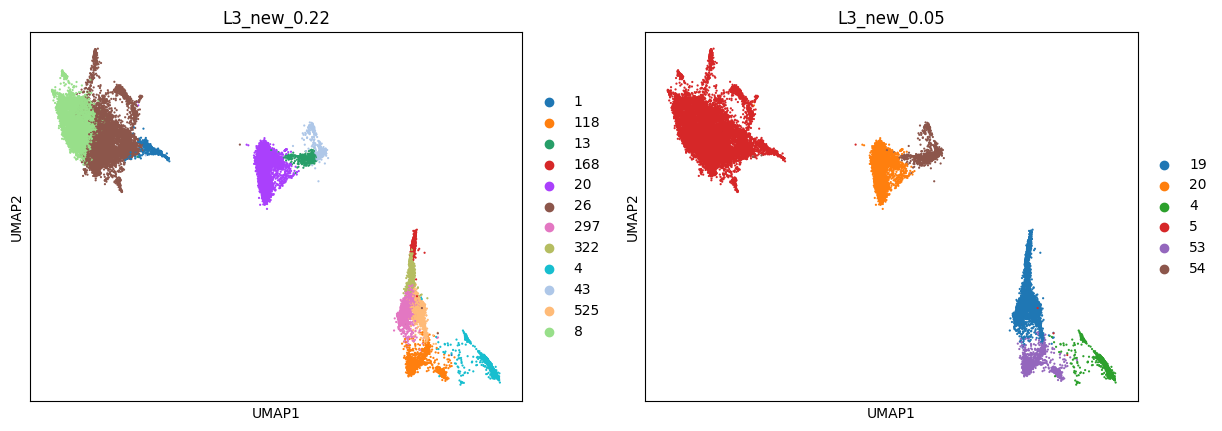

In [17]:
zoom_umap(adata, interest_mask = np.ones(adata.n_obs, dtype=bool), color=["L3_new_0.22", "L3_new_0.05"], ncols=2, include_background=False, clip_pct=0.01, s=10)

In [18]:
adata.obs["L3_new_manual"] = adata.obs["L3_new_0.22"].astype(str).copy() 
# use coarse resolution for VLMCs that were defined on L2
adata.obs.loc[adata.obs[final_l2_col] == "0", "L3_new_manual"] = adata.obs.loc[adata.obs[final_l2_col] == "0", "L3_new_0.05"]

... storing 'L3_new_manual' as categorical


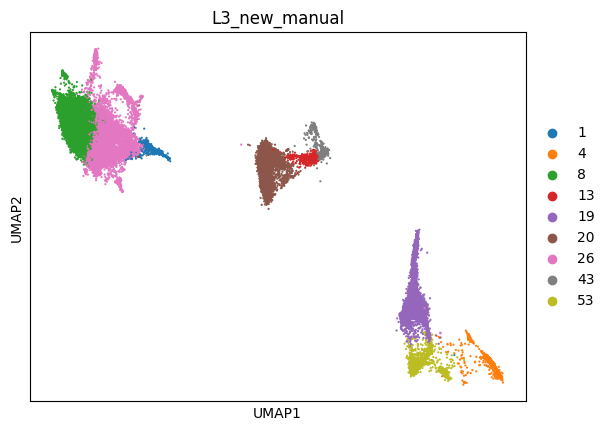

In [20]:
final_l3_col = "L3_new_manual"
zoom_umap(adata, interest_mask = np.ones(adata.n_obs, dtype=bool), color=[final_l3_col], ncols=1, include_background=False, clip_pct=0.01, s=10)

### Decomposing L3 

Allowing for asymmetric marker genes during pruning.

In [21]:
symmetric = parameters["pruning"]["symmetric_highest_resolution"]

for res in [0.1]: 

    labelmat = run_decomposition(
        adata,
        use_rep = parameters["neighbors"]["use_rep"],
        init_key = final_l3_col,
        max_levels = 20,
        n_neighbors = parameters["neighbors"]["n_neighbors"],
        resolutions = [res],
        n_seeds = parameters["leiden"]["n_seeds"],
        n_iterations = parameters["leiden"]["n_iterations"],
        n_jobs = parameters["leiden"]["n_jobs"],
        strata_key = parameters["pruning"]["strata_key"],
        nn_checks = parameters["pruning"]["nn_checks"],
        min_cluster_size = parameters["pruning"]["min_cluster_size"],
        min_stratum_size = parameters["pruning"]["min_stratum_size"],
        max_stratum_size = parameters["pruning"]["max_stratum_size"],
        min_strata = parameters["pruning"]["min_strata"],
        min_pct_expression = parameters["pruning"]["min_pct_expression"],
        min_specificity = parameters["pruning"]["min_specificity"],
        significance_threshold = parameters["pruning"]["significance_threshold"],
        min_marker_genes = parameters["pruning"]["min_marker_genes"],
        symmetric = symmetric,
        masking_enabled = parameters["masking"]["enabled"],
        min_nn_agreement = parameters["masking"]["min_nn_agreement"],
        random_state = parameters["pruning"]["random_state"],
        level=11 # start at level idx 11 as you have decomposed up to 10th level before
    )

    labelmat = pd.Series(labelmat[:, -1], index=adata.obs.index).replace('-1', pd.NA).astype("category")

    adata.obs[f"L4_new_{res}_asym"] = labelmat

0 vs 1 passed with 69 markers
0 vs 1 passed with 38 markers
0 or 1 merged due to insufficient cluster size 1111/90.
	>>1 and 0 merged to make 1_0
0 and 1 merged due to insufficient valid overlapping strata.
	>>1 and 0 merged to make 1_0
0 vs 2 passed with 666 markers
0 or 1 merged due to insufficient cluster size 1124/27.
	>>1 and 0 merged to make 1_0
2 vs 1_0 passed with 658 markers
1 vs 2 passed with 344 markers
0 vs 2 passed with 192 markers
0 vs 1 FAILED with 13 markers
	>>1 and 0 merged to make 1_0
2 vs 1_0 passed with 358 markers
0 vs 1 passed with 195 markers
0 or 2 merged due to insufficient cluster size 713/41.
	>>2 and 0 merged to make 2_0
1 vs 2_0 passed with 187 markers
Step finished with  26.57% of obs locked and 14 clusters.                                                                                           
0 or 1 merged due to insufficient cluster size 713/41.
	>>1 and 0 merged to make 1_0
0 or 1 merged due to insufficient cluster size 1124/27.
	>>1 and 0 merged t

... storing 'L3_new_manual' as categorical


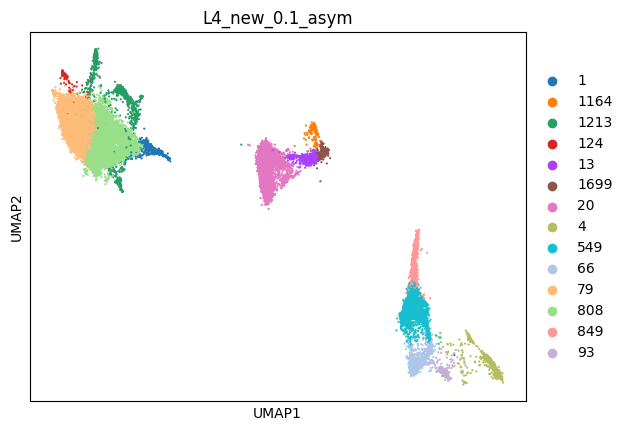

In [22]:
final_l4_col = "L4_new_0.1_asym" 
zoom_umap(adata, interest_mask = np.ones(adata.n_obs, dtype=bool), color=[final_l4_col], ncols=2, include_background=False, clip_pct=0.01, s=10)

Below, plotting marker genes for pericytes, smooth muscle cells as well as endothelial cells from [here](https://www.nature.com/articles/nature25739).

In the light of the co-expression of those marker genes, we flagged the cells on top of the EC cells as doubets and set their labels NaN as to be removed later.

... storing 'L3_new_manual' as categorical


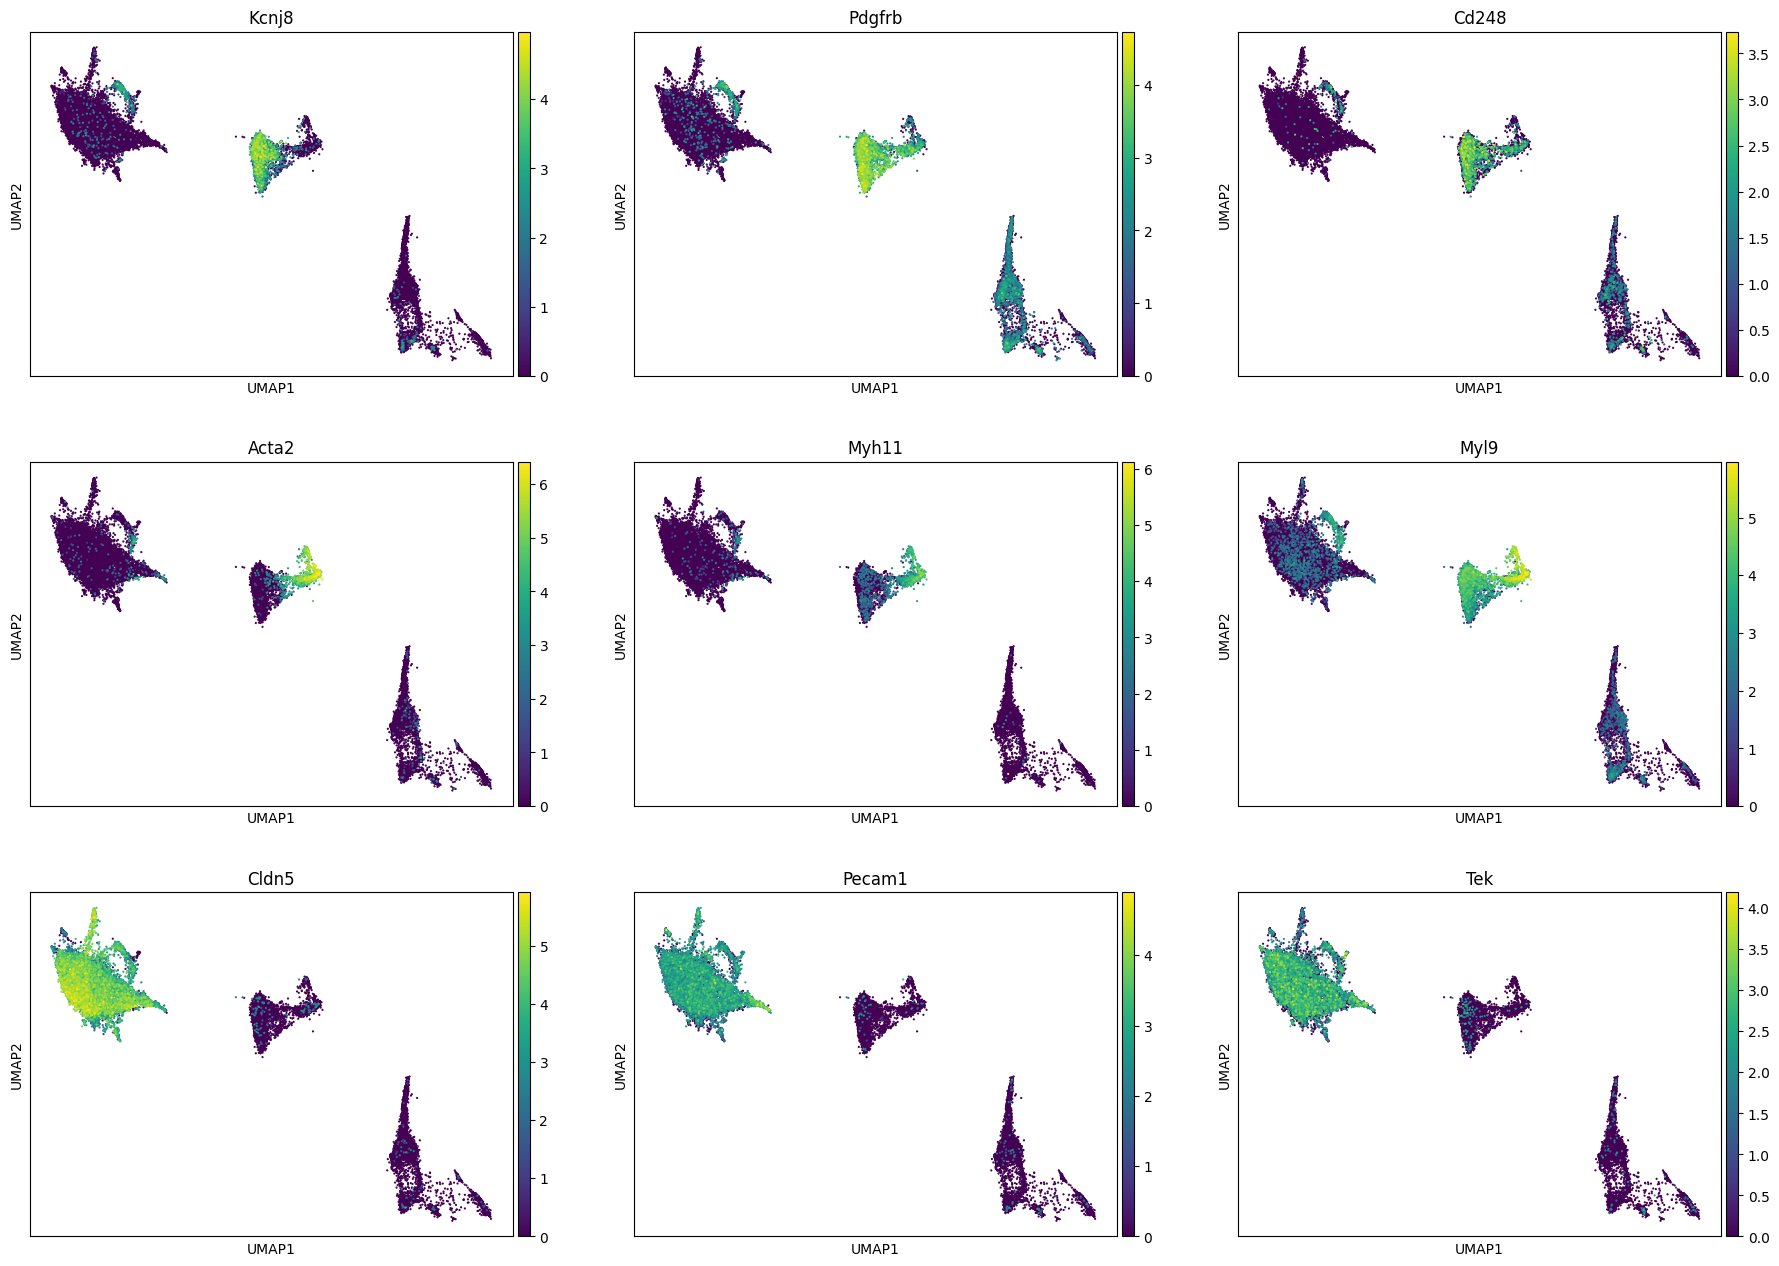

In [23]:
peri_genes = ["Kcnj8", "Pdgfrb", "Cd248"]
smc_genes = ["Acta2", "Myh11",  "Myl9",]
ec_genes = ["Cldn5", "Pecam1", "Tek"]

zoom_umap(adata, interest_mask = np.ones(adata.n_obs, dtype=bool), 
    color=peri_genes + smc_genes + ec_genes, 
    ncols=3, include_background=False, clip_pct=0.01, s=10, layer="log1p")


As to grab the cells, we use a helper object, clustering the EC cells as to flag the cells in question.

In [24]:
helper_adata = adata[adata.obs[final_l4_col] == "1213"].copy()

In [25]:
sc.pp.neighbors(helper_adata, use_rep="X_embed", n_neighbors=15)
sc.tl.leiden(helper_adata, resolution=0.1, flavor="igraph", key_added="helper_leiden")

... storing 'L3_new_manual' as categorical


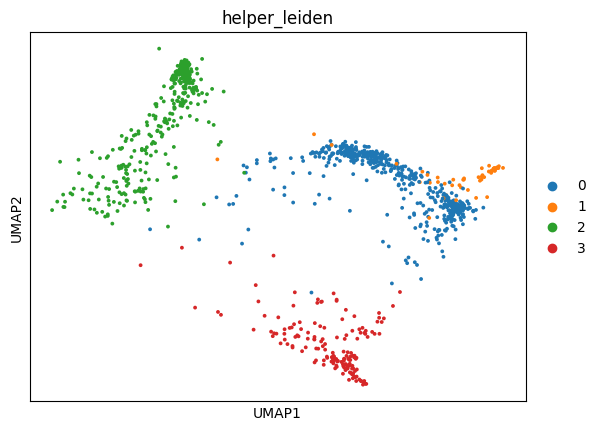

In [26]:
zoom_umap(helper_adata, interest_mask = np.ones(helper_adata.n_obs, dtype=bool), 
    color="helper_leiden", 
    ncols=3, include_background=False, clip_pct=0.001, s=30, )

In [27]:
doublet_cells = list(helper_adata[helper_adata.obs.helper_leiden.isin(["0", "1"])].obs_names)

In [28]:
adata.obs.loc[doublet_cells, final_l2_col] = np.nan
adata.obs.loc[doublet_cells, final_l3_col] = np.nan
adata.obs.loc[doublet_cells, final_l4_col] = np.nan

... storing 'L3_new_manual' as categorical


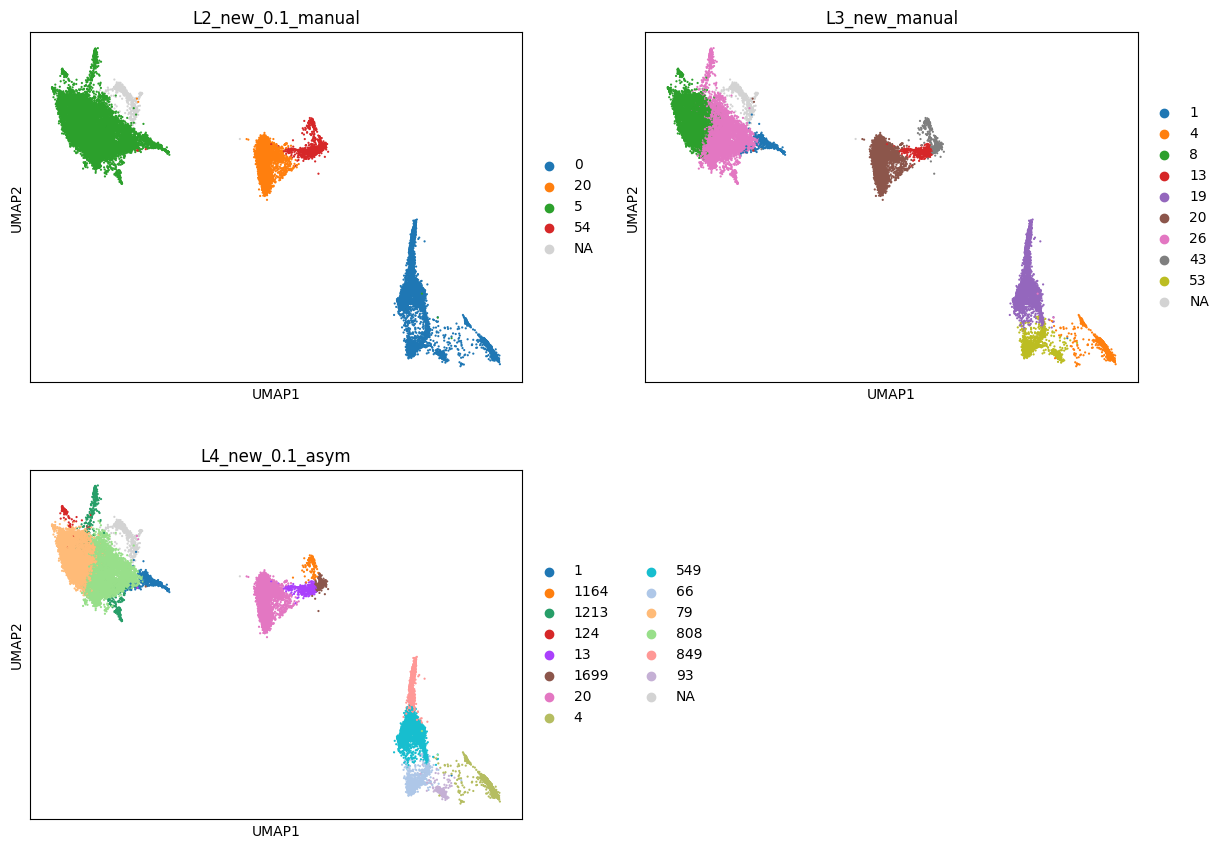

In [29]:
zoom_umap(adata, interest_mask = np.ones(adata.n_obs, dtype=bool), 
    color=[final_l2_col,final_l3_col, final_l4_col, ], 
    ncols=2, include_background=False, clip_pct=0.01, s=10)

### Let's save out the labelmat

In [30]:
final_labelmat = adata.obs.loc[:, [final_l2_col, final_l3_col, final_l4_col]]
final_labelmat.columns=["L2", "L3", "L4"]
final_labelmat.head()

,L2,L3,L4
SC1-01_SAMN18754353_AACCTTTAGAAGCCTG,5,26,808
SC1-01_SAMN18754353_AACCTTTAGCGTGAAC,20,20,20
SC1-01_SAMN18754353_ACGTAGTAGATACATG,20,20,20
SC1-01_SAMN18754353_AGAAGTAGTTATGTCG,0,53,66
SC1-01_SAMN18754353_AGACACTTCCATAAGC,5,26,808


In [ ]:
#final_labelmat.to_csv(CLUSTERING_DIR / "vasc_labelmat.csv")